In [1]:
import mlflow
mlflow.set_tracking_uri("http://localhost:5000")
mlflow.set_experiment("hw-05-ir")

/home/taras-hamkalo/repositories/code/ddw/hamkatar/05/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026/05/08 10:43:36 INFO mlflow.tracking.fluent: Experiment with name 'hw-05-ir' does not exist. Creating a new experiment.


<Experiment: artifact_location='mlflow-artifacts:/5', creation_time=1778229816599, experiment_id='5', last_update_time=1778229816599, lifecycle_stage='active', name='hw-05-ir', tags={}, trace_location=None, workspace='default'>

# Load dataset, parse relevance list, build vocab

In [2]:
import os

from torch.compiler import save_cache_artifacts

document_contents = {}
queries = []

for document_name in os.listdir("../resources/cranfield/d"):
    with open(f"../resources/cranfield/d/{document_name}") as f:
        doc_id = int(document_name.removesuffix(".txt"))
        document_contents[doc_id] = f.read()

for query_name in os.listdir("../resources/cranfield/q"):
    with open(f"../resources/cranfield/q/{query_name}") as q:
        with open(f"../resources/cranfield/r/{query_name}") as r:
            query_id = int(query_name.removesuffix(".txt"))
            relevant_doc_ids = list(map(int, r.readlines()))
            queries.append(
                (
                    query_id,
                    q.read(),
                    relevant_doc_ids
                )
            )

In [3]:
os.makedirs("../outputs", exist_ok=True)

# Define metrics and helper for plotting

In [4]:
ks = [1, 3, 5, 10, 15, 25, 35, 50]

In [5]:
def precision_at_k(retrieved, relevant, k):
    retrieved_k = retrieved[:k]

    relevant_retrieved = sum(
        1 for doc_id in retrieved_k
        if doc_id in relevant
    )

    return relevant_retrieved / k


def recall_at_k(retrieved, relevant, k):
    retrieved_k = retrieved[:k]

    relevant_retrieved = sum(
        1 for doc_id in retrieved_k
        if doc_id in relevant
    )

    return relevant_retrieved / len(relevant)


def f1_score(precision, recall):
    if precision + recall == 0:
        return 0

    return 2 * precision * recall / (precision + recall)


# find position of first relevant document in results
def reciprocal_rank(retrieved, relevant):
    for rank, doc_id in enumerate(retrieved, start=1):
        if doc_id in relevant:
            return 1 / rank

    return 0

In [6]:
import numpy as np


# for each of ks compute avg precision, recall, f1 across all queries
def evaluate_similarity_matrix(
    document_ids,
    similarity_matrix,
    larger_is_better=True
):
    precision_scores = {k: [] for k in ks}
    recall_scores = {k: [] for k in ks}
    f1_scores = {k: [] for k in ks}

    reciprocal_ranks = []

    for q_idx, (query_id, _, relevant_docs) in enumerate(queries):
        relevant_docs = set(relevant_docs)
        scores = similarity_matrix[q_idx]

        if larger_is_better:
            ranked_indices = np.argsort(scores)[::-1]
        else:
            ranked_indices = np.argsort(scores)

        ranked_doc_ids = [
            document_ids[idx]
            for idx in ranked_indices
        ]

        for k in ks:
            precision = precision_at_k(
                ranked_doc_ids,
                relevant_docs,
                k
            )

            recall = recall_at_k(
                ranked_doc_ids,
                relevant_docs,
                k
            )

            f1 = f1_score(precision, recall)

            precision_scores[k].append(precision)
            recall_scores[k].append(recall)
            f1_scores[k].append(f1)

        reciprocal_ranks.append(
            reciprocal_rank(
                ranked_doc_ids,
                relevant_docs
            )
        )

    avg_precision = [
        np.mean(precision_scores[k])
        for k in ks
    ]

    avg_recall = [
        np.mean(recall_scores[k])
        for k in ks
    ]

    avg_f1 = [
        np.mean(f1_scores[k])
        for k in ks
    ]

    mrr = np.mean(reciprocal_ranks)

    return {
        "ks": ks,
        "precision": avg_precision,
        "recall": avg_recall,
        "f1": avg_f1,
        "mrr": mrr
    }

In [7]:
import matplotlib.pyplot as plt


def plot_results(results, title, save_path=None):
    ks = results["ks"]
    plt.figure(figsize=(8, 5))
    plt.plot(
        ks,
        results["precision"],
        marker="o",
        label="Precision@k"
    )

    plt.plot(
        ks,
        results["recall"],
        marker="o",
        label="Recall@k"
    )

    plt.plot(
        ks,
        results["f1"],
        marker="o",
        label="F1@k"
    )

    plt.xlabel("k")
    plt.ylabel("Score")

    plt.title(
        f"{title}\nMRR={results['mrr']:.4f}"
    )

    plt.grid(True)
    plt.legend()
    if save_path:
        plt.savefig(save_path)
    plt.show()

## MlFlow logging helper

In [8]:
import mlflow

def log_to_mlflow(
        run_name,
        method,
        results_cosine,
        results_euclidean,
        csv_file,
        plot_files,
):
    with mlflow.start_run(run_name=run_name):
        mlflow.log_param("dataset_name", "cranfield")
        mlflow.log_param("representation_method", method)
        mlflow.log_param("similarity_scores_recorded", "cosine, euclidean")
        mlflow.log_param("ks", str(ks))

        mlflow.log_metric("cosine_mrr", results_cosine["mrr"])

        for idx, k in enumerate(ks):
            mlflow.log_metric(
                f"cosine_precision_at_{k}",
                results_cosine["precision"][idx]
            )

            mlflow.log_metric(
                f"cosine_recall_at_{k}",
                results_cosine["recall"][idx]
            )

            mlflow.log_metric(
                f"cosine_f1_at_{k}",
                results_cosine["f1"][idx]
            )


        mlflow.log_metric("euclidean_mrr", results_euclidean["mrr"])

        for idx, k in enumerate(ks):
            mlflow.log_metric(
                f"euclidean_precision_at_{k}",
                results_euclidean["precision"][idx]
            )

            mlflow.log_metric(
                f"euclidean_recall_at_{k}",
                results_euclidean["recall"][idx]
            )

            mlflow.log_metric(
                f"euclidean_f1_at_{k}",
                results_euclidean["f1"][idx]
            )


        mlflow.log_artifact(csv_file)
        for plot_file in plot_files:
            mlflow.log_artifact(plot_file, artifact_path="plots")

        print(f"Logged {run_name} to MLflow")


# Binary vector representation

In [9]:
from sklearn.feature_extraction.text import CountVectorizer

binary_vectorizer = CountVectorizer(binary=True)

document_matrix = binary_vectorizer.fit_transform(
    document_contents.values()
)

query_matrix = binary_vectorizer.transform(
    [query_text for _, query_text, _ in queries]
)

In [10]:
feature_names = binary_vectorizer.get_feature_names_out()
for f in feature_names[510:520]:
    print(f)

print("Features count:", len(feature_names))

ability
abilityto
abillowing
ablade
ablating
ablatingmaterial
ablatingsurfaces
ablation
ablationof
ablationover
Features count: 20524


## Compute cosine and Euclidean similarities

In [11]:
from sklearn.metrics.pairwise import cosine_similarity, euclidean_distances

cosine_sim = cosine_similarity(query_matrix, document_matrix)
euclidean_sim = euclidean_distances(query_matrix, document_matrix)

## Build results csv

In [12]:
import pandas as pd

rows = []

for q_idx, q_tuple in enumerate(queries):
    for d_idx, d_id in enumerate(document_contents.keys()):
        rows.append({
            "query_id": q_tuple[0],
            "document_id": d_id,
            "is_relevant": d_id in q_tuple[2],
            "cosine": cosine_sim[q_idx][d_idx],
            "euclidean": euclidean_sim[q_idx][d_idx]
        })

df = pd.DataFrame(rows)
df.to_csv("../outputs/binary-repr-results.csv", index=False)
df.head()

,query_id,document_id,is_relevant,cosine,euclidean
0,1,1,False,0.000000,9.486833
1,1,10,False,0.000000,7.000000
2,1,100,False,0.051640,11.532563
3,1,1000,False,0.027156,11.090537
4,1,1001,False,0.000000,9.110434


## Metrics

In [13]:
cosine_results = evaluate_similarity_matrix(
    list(document_contents.keys()),
    cosine_sim,
    larger_is_better=True
)
print("Cosine MRR:", cosine_results["mrr"])

Cosine MRR: 0.479598152637297


In [14]:
euclidean_results = evaluate_similarity_matrix(
    list(document_contents.keys()),
    euclidean_sim,
    larger_is_better=False
)

print("Euclidean MRR:", euclidean_results["mrr"])

Euclidean MRR: 0.044940405001506034


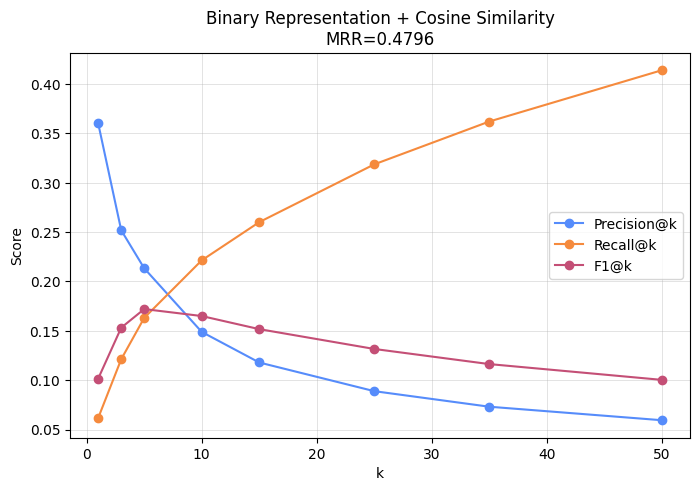

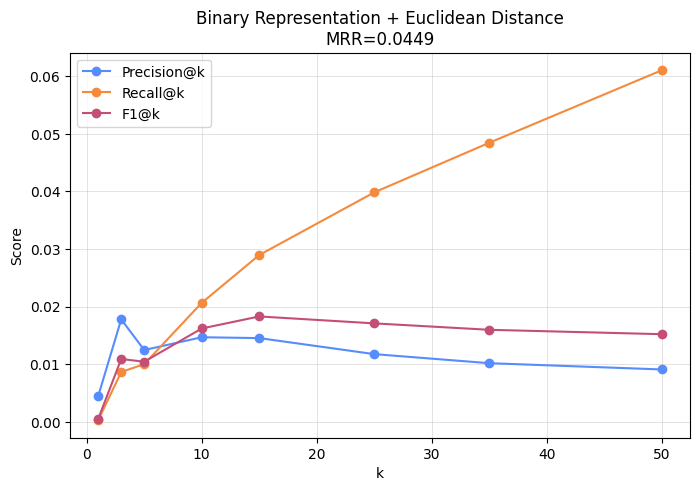

In [15]:
plot_results(
    cosine_results,
    "Binary Representation + Cosine Similarity",
    save_path="../outputs/binary-cosine.png",
)

plot_results(
    euclidean_results,
    "Binary Representation + Euclidean Distance",
    save_path="../outputs/binary-euclidean.png",
)

In [16]:
log_to_mlflow("binary", "binary", cosine_results, euclidean_results, "../outputs/binary-repr-results.csv", ["../outputs/binary-cosine.png", "../outputs/binary-euclidean.png"])

Logged binary to MLflow
🏃 View run binary at: http://localhost:5000/#/experiments/5/runs/c5e4c3f5664248a891a6f7b63c95d940
🧪 View experiment at: http://localhost:5000/#/experiments/5


# TF

In [17]:
tf_vectorizer = CountVectorizer(binary=False)

document_matrix = tf_vectorizer.fit_transform(
    document_contents.values()
)
query_matrix = tf_vectorizer.transform(
    [query_text for _, query_text, _ in queries]
)

cosine_sim = cosine_similarity(query_matrix, document_matrix)
euclidean_sim = euclidean_distances(query_matrix, document_matrix)

## Build csv

In [18]:
rows = []
for q_idx, q_tuple in enumerate(queries):
    for d_idx, d_id in enumerate(document_contents.keys()):
        rows.append({
            "query_id": q_tuple[0],
            "document_id": d_id,
            "is_relevant": d_id in q_tuple[2],
            "cosine": cosine_sim[q_idx][d_idx],
            "euclidean": euclidean_sim[q_idx][d_idx]
        })
df = pd.DataFrame(rows)

df.to_csv(
    "../outputs/tf-repr-results.csv",
    index=False
)

df.head()

,query_id,document_id,is_relevant,cosine,euclidean
0,1,1,False,0.000000,19.974984
1,1,10,False,0.000000,9.643651
2,1,100,False,0.084875,30.512293
3,1,1000,False,0.013358,21.840330
4,1,1001,False,0.000000,17.521415


## Metrics

In [19]:
cosine_results = evaluate_similarity_matrix(
    list(document_contents.keys()),
    cosine_sim,
    larger_is_better=True
)

euclidean_results = evaluate_similarity_matrix(
    list(document_contents.keys()),
    euclidean_sim,
    larger_is_better=False
)

print("TF + Cosine MRR:", cosine_results["mrr"])

print("TF + Euclidean MRR:", euclidean_results["mrr"])

TF + Cosine MRR: 0.40448369727883954
TF + Euclidean MRR: 0.04345530632833024


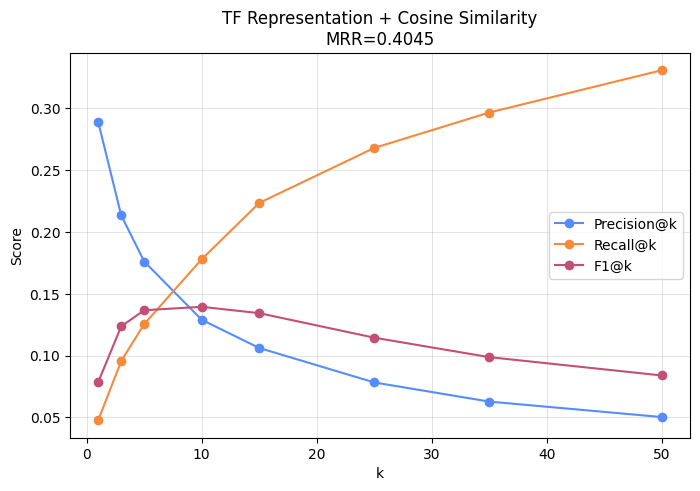

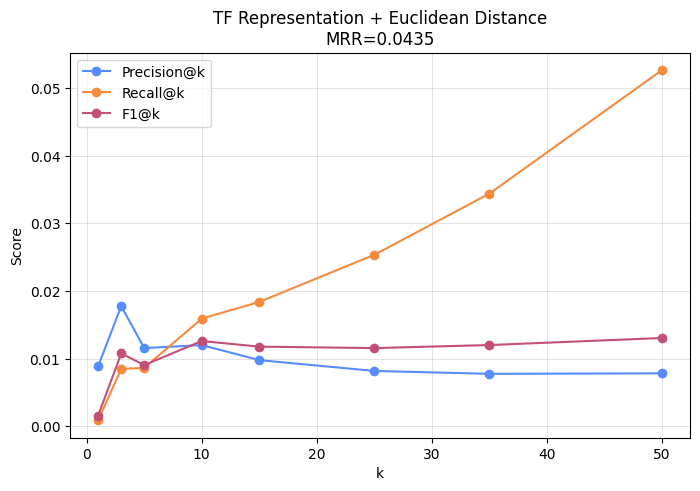

In [20]:
plot_results(
    cosine_results,
    "TF Representation + Cosine Similarity",
    save_path="../outputs/tf-cosine.png"
)

plot_results(
    euclidean_results,
    "TF Representation + Euclidean Distance",
    save_path="../outputs/tf-euclidean.png"
)

In [21]:
log_to_mlflow("tf", "tf", cosine_results, euclidean_results, "../outputs/tf-repr-results.csv", ["../outputs/tf-cosine.png", "../outputs/tf-euclidean.png"])

Logged tf to MLflow
🏃 View run tf at: http://localhost:5000/#/experiments/5/runs/dee75eaf286f448ba7ce7b660cb433b8
🧪 View experiment at: http://localhost:5000/#/experiments/5


# Tf-idf

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_vectorizer = TfidfVectorizer()
document_matrix = tfidf_vectorizer.fit_transform(
    document_contents.values()
)
query_matrix = tfidf_vectorizer.transform(
    [query_text for _, query_text, _ in queries]
)

cosine_sim = cosine_similarity(query_matrix, document_matrix)
euclidean_sim = euclidean_distances(query_matrix, document_matrix)

## Build csv

In [23]:
rows = []
for q_idx, q_tuple in enumerate(queries):
    for d_idx, d_id in enumerate(document_contents.keys()):
        rows.append({
            "query_id": q_tuple[0],
            "document_id": d_id,
            "is_relevant": d_id in q_tuple[2],
            "cosine": cosine_sim[q_idx][d_idx],
            "euclidean": euclidean_sim[q_idx][d_idx]
        })
df = pd.DataFrame(rows)

df.to_csv(
    "../outputs/tf-idf-repr-results.csv",
    index=False
)

df.head()

,query_id,document_id,is_relevant,cosine,euclidean
0,1,1,False,0.000000,1.414214
1,1,10,False,0.000000,1.414214
2,1,100,False,0.086719,1.351504
3,1,1000,False,0.003271,1.411899
4,1,1001,False,0.000000,1.414214


## Metrics

In [24]:
cosine_results = evaluate_similarity_matrix(
    list(document_contents.keys()),
    cosine_sim,
    larger_is_better=True
)

euclidean_results = evaluate_similarity_matrix(
    list(document_contents.keys()),
    euclidean_sim,
    larger_is_better=False
)

print("TF-IDF + Cosine MRR:", cosine_results["mrr"])

print("TF-IDF + Euclidean MRR:", euclidean_results["mrr"])

TF-IDF + Cosine MRR: 0.6718107182713381
TF-IDF + Euclidean MRR: 0.2573499398556413


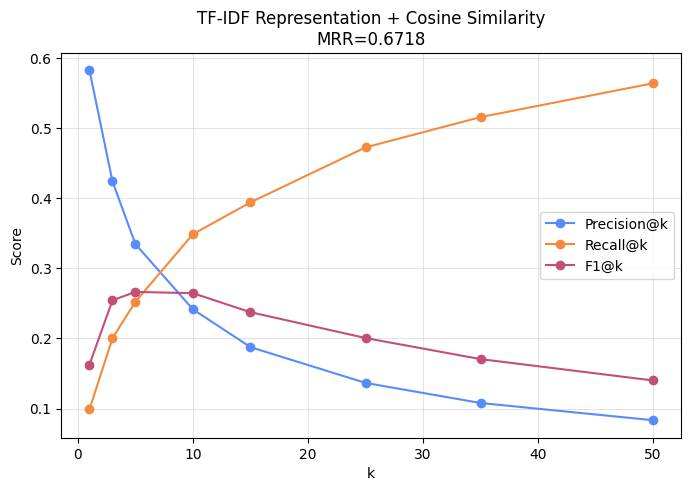

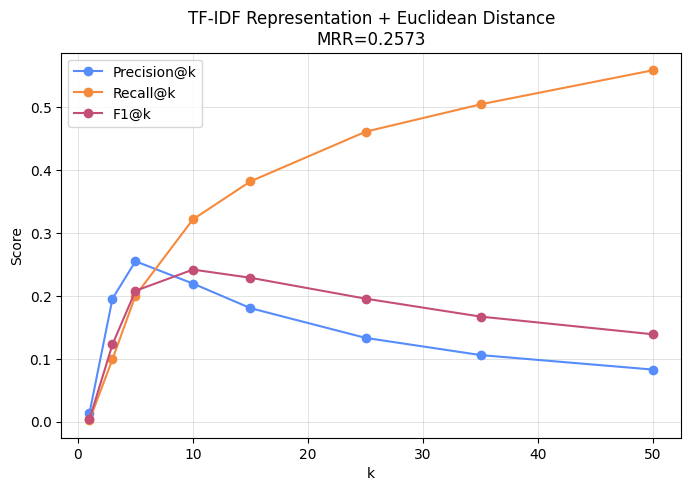

In [25]:
plot_results(
    cosine_results,
    "TF-IDF Representation + Cosine Similarity",
    save_path="../outputs/tf-idf-cosine.png"
)

plot_results(
    euclidean_results,
    "TF-IDF Representation + Euclidean Distance",
    save_path="../outputs/tf-idf-euclidean.png"
)

In [26]:
log_to_mlflow("tf-idf", "tf-idf", cosine_results, euclidean_results, "../outputs/tf-idf-repr-results.csv", ["../outputs/tf-idf-cosine.png", "../outputs/tf-idf-euclidean.png"])

Logged tf-idf to MLflow
🏃 View run tf-idf at: http://localhost:5000/#/experiments/5/runs/b0fb49cf84c744e28223bcfe18aed06b
🧪 View experiment at: http://localhost:5000/#/experiments/5


# Dense representations

In [27]:
from sentence_transformers import SentenceTransformer

model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2"
)

/home/taras-hamkalo/repositories/code/ddw/hamkatar/05/.venv/lib/python3.12/site-packages/torch/cuda/__init__.py:180: UserWarning: CUDA initialization: Unexpected error from cudaGetDeviceCount(). Did you run some cuda functions before calling NumCudaDevices() that might have already set an error? Error 804: forward compatibility was attempted on non supported HW (Triggered internally at /pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return torch._C._cuda_getDeviceCount() > 0
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 13879.50it/s]


In [28]:
document_embeddings = model.encode(
    list(document_contents.values()),
    show_progress_bar=True
)

query_embeddings = model.encode(
    [query_text for _, query_text, _ in queries],
    show_progress_bar=True
)

Batches: 100%|██████████| 8/8 [00:00<00:00, 25.57it/s]


In [29]:
document_embeddings.shape

(1400, 384)

In [30]:
cosine_sim = cosine_similarity(
    query_embeddings,
    document_embeddings
)

euclidean_sim = euclidean_distances(
    query_embeddings,
    document_embeddings
)

## Build csv

In [31]:
rows = []
for q_idx, q_tuple in enumerate(queries):
    for d_idx, d_id in enumerate(document_contents.keys()):
        rows.append({
            "query_id": q_tuple[0],
            "document_id": d_id,
            "is_relevant": d_id in q_tuple[2],
            "cosine": cosine_sim[q_idx][d_idx],
            "euclidean": euclidean_sim[q_idx][d_idx]
        })
df = pd.DataFrame(rows)

df.to_csv(
    "../outputs/dense-repr-results.csv",
    index=False
)

df.head()

,query_id,document_id,is_relevant,cosine,euclidean
0,1,1,False,0.294260,1.188057
1,1,10,False,0.228490,1.242184
2,1,100,False,0.296573,1.186109
3,1,1000,False,0.355938,1.134955
4,1,1001,False,0.297337,1.185464


## Metrics

In [32]:
cosine_results = evaluate_similarity_matrix(
    list(document_contents.keys()),
    cosine_sim,
    larger_is_better=True
)

euclidean_results = evaluate_similarity_matrix(
    list(document_contents.keys()),
    euclidean_sim,
    larger_is_better=False
)

print("Dense + Cosine MRR:", cosine_results["mrr"])

print("Dense + Euclidean MRR:", euclidean_results["mrr"])

Dense + Cosine MRR: 0.7332458484860571
Dense + Euclidean MRR: 0.7332458484860571


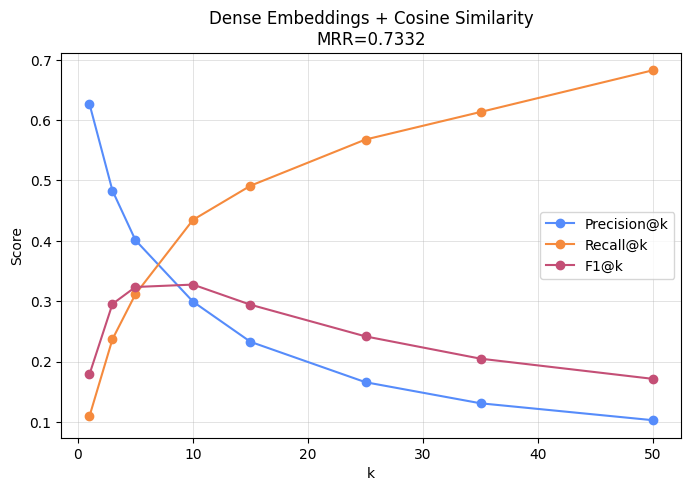

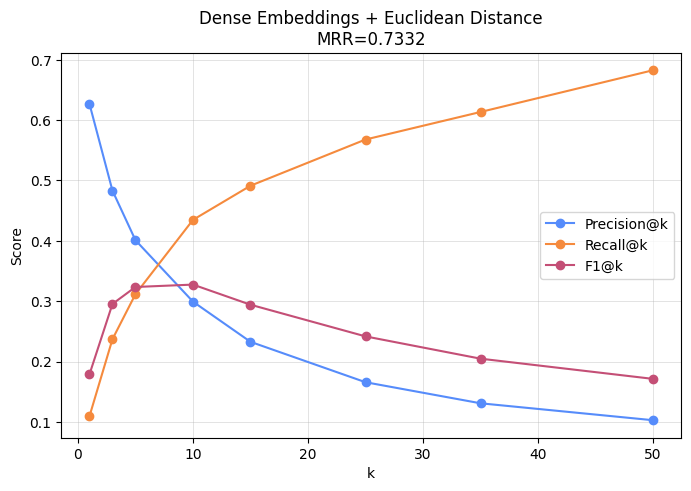

In [33]:
plot_results(
    cosine_results,
    "Dense Embeddings + Cosine Similarity",
    save_path="../outputs/dense-cosine.png"
)

plot_results(
    euclidean_results,
    "Dense Embeddings + Euclidean Distance",
    save_path="../outputs/dense-euclidean.png"
)

In [34]:
log_to_mlflow("dense", "dense", cosine_results, euclidean_results, "../outputs/dense-repr-results.csv", ["../outputs/dense-cosine.png", "../outputs/dense-euclidean.png"])

Logged dense to MLflow
🏃 View run dense at: http://localhost:5000/#/experiments/5/runs/0d6964b5d77d40dea313fae997a4ccd3
🧪 View experiment at: http://localhost:5000/#/experiments/5
